# Demonstrating Extreme Illumination Perturbations

## Introduction
This notebook is part of the NRTK demonstration suite, demonstrating how perturbations can be applied and their impact measured via MAITE evaluation workflows.

## Layout
This notebook demonstrates how a particular condition (in this case, <b><i>extreme illumination conditions</i></b>), can affect an object detection model, and how that impact can be measured. The overall structure is:

- **Evaluation Guidance: Computing Mean Average Precision (mAP):**
    - An overview of the evaluation strategy.
- **Setup:**
    - Notebook initialization, loading the supporting python code. If this is the first time you've run this notebook, this may take some time.
    - Loading the source image and its precomputed "ground truth" detections, which will be used throughout the notebook.
- **Image Perturbation Examples:**
    - The NRTK perturbation is demonstrated on the source image.
- **Baseline Detections:**
    - The object detection model is loaded, ready for use throughout the rest of the notebook. **Note**: The dataset's "ground truth" detections were generated using this same model and not created by hand.
 
At this point, we have the fundamental elements of our evaluation: the model, our reference image, and a mechanism for creating the perturbed test images. Next we adapt these elements to be used with the MAITE evaluation workflow:

- **Wrapping the Detection Model**
- **Wrapping the Perturbation as Augmentation Objects**
- **Wrapping the Metrics**

After the evaluation elements have been wrapped, we can run the evaluation:

- **Preparing the Augmentations:**
    - We specify the range of perturbation values to evaluate and optionally specify which ones we'd like to visualize.
- **Evaluation of Augmented Data:**
    - Each augmentation is run through MAITE's evaluation workflow, computing the absolute mAP metric of the detector on the perturbed datasets.
- **Evaluation Analysis:**
    - We plot and discuss the mAP@50 metric from each of the perturbed images, as well as per-class and per-area results.

To run this notebook in Colab, use the link below:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kitware/nrtk/blob/main/docs/examples/maite/extreme_illumination.ipynb)

## Evaluation Guidance: Computing Mean Average Precision (mAP)

This notebook evaluates the robustness of an Object Detector when exposed to NRTK (Natural, Physics-based) perturbations, using mean Average Precision (mAP) as the performance metric. The baseline case, where no perturbations are applied (identity augmentation), typically yields an mAP close to 1.0 and serves as the reference point. Unlike standard evaluations that focus on whether the detector can correctly identify and localize objects, our goal here is to measure how well the detector maintains its performance under realistic perturbations. 

By comparing the absolute mAP scores of the baseline against perturbed datasets, we can assess the detector's sensitivity to environmental variations and quantify its robustness in generating reliable predictions beyond controlled conditions.

## Setup: Notebook Initialization
The next few cells import the python packages used in the rest of the notebook.

```{note}
We are suppressing warnings within this notebook to reduce visual clutter for demonstration purposes. If any issues arise while executing this notebook, we recommend that the first cell is **not** executed so that any related warnings are shown.
```

In [1]:
from __future__ import annotations

# warning suppression
import warnings

warnings.filterwarnings("ignore")

```{important}
This notebook requires NRTK with the following extra(s):

- `maite`: MAITE library providing evaluation capability and interoperability with other JATIC tools
- `pillow`: Image library for opening, saving, and editing image files
- `tools`: datamaite library for loading the object detection dataset

The next cell will install these extra(s). See [Installation](<project:/getting_started/installation.rst>) for alternatives.
```

In [2]:
%pip install -qU pip
print("Installing nrtk with required extras...")
%pip install -q "nrtk[maite,pillow,tools]"
print("Installing notebook-specific packages...")
%pip install -q matplotlib torchvision torchmetrics ultralytics

# ultralytics pulls in opencv-python (non-headless), which requires libGL and
# fails in headless environments (e.g. CI). Replace it with the headless variant.
print("Replacing opencv-python with headless variant...")
%pip uninstall -qy opencv-python opencv-python-headless
%pip install -q opencv-python-headless --no-cache-dir

print("Done!")

from nrtk.utils._extras import print_extras_status  # noqa: E402 - intentionally after %pip install

print_extras_status()

Note: you may need to restart the kernel to use updated packages.
Installing nrtk with required extras...


Note: you may need to restart the kernel to use updated packages.
Installing notebook-specific packages...


Note: you may need to restart the kernel to use updated packages.
Replacing opencv-python with headless variant...


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.
Done!


Detected status of NRTK extras and their dependencies:



[albumentations]
  - nrtk-albumentations       ✗ missing

[diffusion]
  - torch                     ✓ 2.14.1
  - diffusers                 ✗ missing
  - accelerate                ✗ missing
  - Pillow                    ✓ 13.0.0
  - transformers              ✗ missing
  - protobuf                  ✗ missing

[graphics]
  - opencv-python             ✗ missing

[hcipy]
  - hcipy                     ✗ missing
  - scipy                     ✓ 1.18.1
  - xxhash                    ✗ missing

[headless]
  - opencv-python-headless    ✓ 5.0.0.93

[maite]
  - maite                     ✓ 0.10.3

[pillow]
  - Pillow                    ✓ 13.0.0

[pyav]
  - av                        ✓ 17.1.0

[pybsm]
  - pybsm                     ✗ missing

[skimage]
  - scikit-image              ✗ missing

[tools]
  - kwcoco                    ✓ 0.9.1
  - Pillow                    ✓ 13.0.0
  - click                     ✓ 8.5.0
  - fastapi                   ✓ 0.162.0
  - uvicorn                   ✓ 0.54.0
  - pydantic

    https://nrtk.readthedocs.io/en/stable/



```{note}
**Colab users**: After setting up the environment, you may need to "Restart Runtime" in order to resolve package version conflicts (see the [README](https://github.com/Kitware/nrtk/blob/main/docs/examples/README.md#run-the-notebooks-from-colab) for more info).
```

In [3]:
import os
import urllib.request
import zipfile
from collections.abc import Sequence
from typing import Any, cast

import numpy as np
from datamaite import load_od

# some initial imports
%matplotlib inline
%config InlineBackend.figure_format = "jpeg"  # Use JPEG format for inline visualizations

from matplotlib import pyplot as plt

from nrtk.impls.perturb_image.photometric.enhance import BrightnessPerturber  # requires `pillow` extra

## Setup: Source Image

In the next cell, we'll download a dataset comprised of a single source image from the __[VisDrone](https://github.com/VisDrone/VisDrone-Dataset)__ dataset, along with its ground truth object detections. The dataset will be cached in a local `data` subdirectory.

### A Note on Image Storage

Typically in ML workflows, batches of images are processed as tensors of the color channels. Both our perturber (NRTK) and object detector (YOLO) accept numpy `ndarray` objects, and we will use [matplotlib.imshow](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) to view them. The complication is that YOLO [expects the color channels to be in BGR](https://docs.ultralytics.com/modes/predict) order. If we naively view the same data YOLO inferences on, the colors will be wrong; if we naively inference on what we view, the detections will be wrong. (Our NRTK perturbation is agnostic to the channel order.)

`datamaite` decodes images as RGB arrays so we'll keep our image in RGB order throughout the notebook. We will only convert to BGR at the few places we call YOLO directly on a raw array.

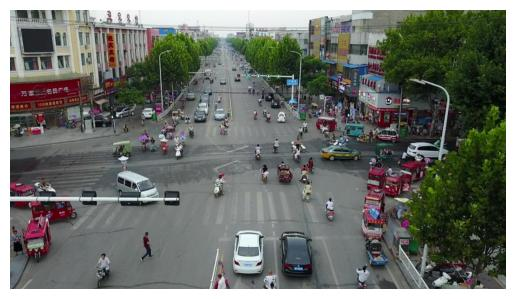

In [4]:
# The visdrone_coco dataset (image + ground truth detections) lives in this notebook's data subdirectory.
data_dir = "./data"
os.makedirs(data_dir, exist_ok=True)
dataset_dir = os.path.join(data_dir, "visdrone_coco")
if not os.path.isdir(dataset_dir):
    # The Girder folder download streams a zip whose root folder is
    # visdrone_coco/, so extracting into data_dir creates dataset_dir.
    url = "https://data.kitware.com/api/v1/folder/6ab4270e92470417fec95d0a/download"
    zip_path = os.path.join(data_dir, "visdrone_coco.zip")
    _ = urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(data_dir)
    os.remove(zip_path)

# A datamaite dataset comprised of our source image and its precomputed ground truth detections
single_image_dataset = load_od(dataset_dir, dataset_format="coco")
img_rgb = np.transpose(single_image_dataset.get_input(0), (1, 2, 0))  # datamaite decodes as (C, H, W) RGB

plt.figure()
plt.axis("off")
_ = plt.imshow(img_rgb)

## NRTK Brightness Perturbation: Examples and Guidance

The [Brightness perturber](<project:/reference/api/_implementations/nrtk.impls.perturb_image.photometric.enhance.BrightnessPerturber.rst>) perturbation is set by a single floating point value `f`:

- `f == 0.0` (the minimum value): returns a black image.
- `0.0 < f < 1.0`: returns an image dimmer than the original.
- `f == 1.0`: returns the original image unchanged.
- `f > 1.0`: returns an image brighter than the original. There is no upper bound, but values greater than 2 or 3 start to wash out objects in a typical image, as seen below.
  

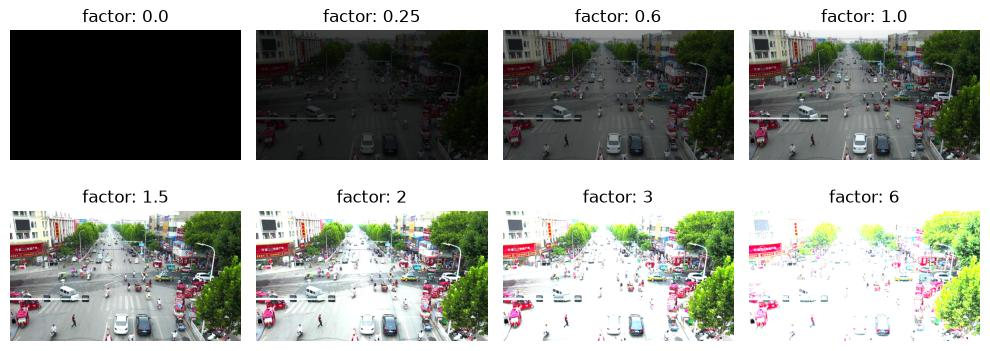

In [5]:
_, ax = plt.subplots(2, 4, figsize=(10, 4))
for idx, f in enumerate((0.0, 0.25, 0.6, 1.0, 1.5, 2, 3, 6)):
    (row, col) = (int(idx / 4), idx % 4)
    bp = BrightnessPerturber(factor=f)
    ax[row, col].set_title(f"factor: {f}")
    ax[row, col].imshow(bp(image=img_rgb)[0])
    _ = ax[row, col].axis("off")
plt.tight_layout()

## Baseline Detections

Our ground truth detections are stored as a **COCO dataset** on disk (`data/visdrone_coco`). Rather than re-running the detector on every execution, we simply load those detections with `datamaite`; they serve as the "ground truth" for comparison against the perturbed images. We still load the [YOLOv11](https://docs.ultralytics.com/models/yolo11) model below -- that is the detector that gets *evaluated* on the perturbed images.

In [6]:
# Import YOLO support
import ultralytics

ultralytics.checks()
print("Downloading model...")
model = ultralytics.YOLO("yolo11n.pt")

Ultralytics 8.4.190 🚀 Python-3.13.2 torch-2.14.1 CPU (Apple M2)


Setup complete ✅ (8 CPUs, 16.0 GB RAM, 357.0/460.4 GB disk)


## MAITE Evaluation Workflow Preparation

We'll use the [MAITE Evaluation workflow](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/tasks/generic.py#L190) to evaluate the performance of the perturbed data against our baseline detections. We'll need to "wrap" our model, data, and perturbations into callable objects to pass to the `maite.tasks.evaluate` function:

- We'll wrap the **model** to make predictions on input data when called.

- The wrapped **dataset** will return our test image when called. Note that this will be the original, unperturbed image; we'll apply our perturbations via the **augmentation** object, which applies the perturbation to the image inside the evaluation.

- Finally, the **metric** object will define our precise scoring methodology.

The evaluation workflow in this notebook is slightly unusual. Typical ML workflows apply many different augmentations / perturbations to much larger datasets, and only call `evaluate` once to get a statistical view of performance. Since the goal of this notebook is to drill down into how perturbation affects performance, we've essentially flipped the process, calling `evaluate` (and thus our wrapped objects) many times, once per loop on our single image perturbed to a known degree, and then observing how the metrics respond.

### A Helper Class

The following cell adds a helper class to allow us to use YOLO detections within the MAITE evaluation workflow.
The `YOLODetectionTarget` helper class stores the bounding boxes, label indices, and confidence scores for a single image's detections.

In [7]:
from dataclasses import dataclass

import torch

##
## Helper class for containing the boxes, label indices, and confidence scores.
##


@dataclass
class YOLODetectionTarget:
    """A helper class to represent object detection results in the format expected by YOLO-based models.

    Attributes:
        boxes (torch.Tensor): A tensor containing the bounding boxes for detected objects in
            [x_min, y_min, x_max, y_max] format.
        labels (torch.Tensor): A tensor containing the class labels for the detected objects.
            These may be floats for compatibility with specific datasets or tools.
        scores (torch.Tensor): A tensor containing the confidence scores for the detected objects.
    """

    boxes: torch.Tensor
    labels: torch.Tensor
    scores: torch.Tensor

### (1) Wrapping the Detection Model

The first object we'll wrap will be the detection model. The cell below defines a class adapting YOLO for the [MAITE Object Detection Model](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/protocols/object_detection.py#L376) protocol. The `__call__` method runs the model on images in the batch and is called by the MAITE evaluation workflow later in the notebook.

In [8]:
import maite.protocols.object_detection as od
import ultralytics.models
from maite.protocols import ArrayLike, ModelMetadata


class MaiteYOLODetector:
    """A wrapper class for a YOLO model to simplify its usage with input batches and object detection targets.

    This class takes a YOLO model instance, processes input image batches, and converts predictions into
    `YOLODetectionTarget` instances.

    Attributes:
        _model (ultralytics.models.yolo.model.YOLO): The YOLO model instance used for predictions.

    Methods:
        __call__(batch):
            Processes a batch of images through the YOLO model and returns the predictions as
            `YOLODetectionTarget` instances.
    """

    def __init__(self, model: ultralytics.models.yolo.model.YOLO) -> None:
        """Initializes the MaiteYOLODetector with a YOLO model instance.

        Args:
            model (ultralytics.models.yolo.model.YOLO): The YOLO model to use for predictions.
        """
        self._model = model
        # Dummy model metadata type to pass type checking
        self.metadata = ModelMetadata(id="0")

    def __call__(self, batch: Sequence[ArrayLike]) -> Sequence[YOLODetectionTarget]:
        """Processes a batch of images using the YOLO model and converts the predictions to `YOLODetectionTarget`s.

        Args:
            batch (Sequence[ArrayLike]): A batch of images in (c, h, w) RGB format (channel-first).

        Returns:
            Sequence[YOLODetectionTarget]: A list of YOLODetectionTarget instances containing the predictions for each
            image in the batch.
        """
        # Convert images to channel-last format (h, w, c) and BGR for YOLO model
        batch_transposed = [np.transpose(batch[i], (1, 2, 0))[:, :, ::-1] for i in range(len(batch))]

        yolo_predictions = self._model(batch_transposed, verbose=False)
        return [
            YOLODetectionTarget(
                p.boxes.xyxy.cpu(),  # Bounding boxes in (x_min, y_min, x_max, y_max) format
                p.boxes.cls.cpu(),  # Class indices for the detected objects
                p.boxes.conf.cpu(),  # Confidence scores for the detections
            )
            for p in yolo_predictions
        ]


# create the wrapped model object
yolo_model: od.Model = MaiteYOLODetector(model)

### (2) Wrapping the Perturbations as Augmentations

The `evaluate` function will perturb the image from the dataset using instances of the class defined below, one instance per perturbation value. Note that the object doesn't perform any augmentations until called by the `evaluate` workflow.

In [9]:
from nrtk.interop import MAITEObjectDetectionAugmentation

bp = BrightnessPerturber(factor=1.0)
identity_augmentation = MAITEObjectDetectionAugmentation(augment=bp, augment_id="identity")

### (3) Wrapping the Metrics

We'll compare the detections in each perturbed image to the unperturbed detections using the Mean Average Precision (mAP) metric from the `torchmetrics` package. The following cell creates a mAP metrics object, wraps it in a MAITE [MAITE Object Detection Metric](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/protocols/object_detection.py#L470) protocol-compatible class, and then creates an instance of this class, which will be called by `evaluate`.

This code is copied directly from the [MAITE object detection tutorial](https://github.com/mit-ll-ai-technology/maite/blob/main/examples/tutorials/torchvision_object_detection.ipynb) (with the exception of setting `class_metrics=True`.)

In [10]:
from maite.protocols import MetricMetadata
from torchmetrics import Metric as TorchMetric
from torchmetrics.detection.mean_ap import MeanAveragePrecision

##
## Create an instance of the MAP metric object
##

tm_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.5],
    rec_thresholds=[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    max_detection_thresholds=[1, 10, 100],
    class_metrics=True,
    extended_summary=False,
    average="macro",
)

##
## This wrapper associates the MAP metric object with methods called by the evaluate
## workflow to accumulate detection data and compute the metrics.
##


class WrappedTorchmetricsMetric:
    """A wrapper class for a Torchmetrics metric designed to simplify its usage for object detection tasks.

    This class facilitates the conversion of object detection targets and predictions into the format
    expected by Torchmetrics metrics, allowing for easier integration with existing pipelines.

    Attributes:
        _tm_metric (Callable): The Torchmetrics metric to be wrapped, which takes lists of dictionaries
            containing torch.Tensor objects representing predictions and targets.

    Methods:
        to_tensor_dict(target):
            Converts an `ObjectDetectionTarget` into a dictionary format compatible with the Torchmetrics
            metric's `update` method.

        update(preds, targets):
            Updates the wrapped Torchmetrics metric with batches of predictions and targets in their native format.

        compute():
            Computes the final metric values using the wrapped Torchmetrics metric.

        reset():
            Resets the state of the wrapped Torchmetrics metric.
    """

    def __init__(
        self,
        tm_metric: TorchMetric,
    ) -> None:
        """Initializes the WrappedTorchmetricsMetric with the given Torchmetrics metric.

        Args:
            tm_metric (Callable): A Torchmetrics metric instance that expects predictions and targets as lists of
                dictionaries containing torch.Tensor objects.
        """
        self._tm_metric = tm_metric
        # Dummy metric metadata type to pass type checking
        self.metadata = MetricMetadata(id="0")

    @staticmethod
    def to_tensor_dict(target: od.ObjectDetectionTarget) -> dict[str, torch.Tensor]:
        """Converts an ObjectDetectionTarget into a dictionary format compatible with the Torch's `update` method.

        Args:
            target (od.ObjectDetectionTarget): An object detection target instance containing boxes, labels, and scores.

        Returns:
            dict[str, torch.Tensor]: A dictionary with keys `boxes`, `scores`, and `labels`, each mapping to a tensor.
        """
        return {
            "boxes": torch.as_tensor(target.boxes),
            "scores": torch.as_tensor(target.scores),
            "labels": torch.as_tensor(target.labels).type(torch.int64),
        }

    def update(
        self,
        preds: Sequence[od.TargetType],
        targets: Sequence[od.TargetType],
        _: Sequence[od.DatumMetadataType],
    ) -> None:
        """Updates the wrapped Torchmetrics metric with the given predictions and targets.

        Args:
            preds (Sequence[od.TargetType]): A batch of predictions in the format expected by the Torchmetrics metric.
            targets (Sequence[od.TargetType]): A batch of targets in the format expected by the Torchmetrics metric.
        """
        preds_tm = [self.to_tensor_dict(pred) for pred in preds]
        targets_tm = [self.to_tensor_dict(tgt) for tgt in targets]
        self._tm_metric.update(preds_tm, targets_tm)

    def compute(self) -> dict[str, Any]:
        """Computes and returns the final metric values using the wrapped Torchmetrics metric.

        Returns:
            dict[str, Any]: A dictionary containing the computed metric values.
        """
        return self._tm_metric.compute()

    def reset(self) -> None:
        """Resets the state of the wrapped Torchmetrics metric, clearing any accumulated data."""
        self._tm_metric.reset()


##
## This is our instance variable that can compute the MAP metrics.
##

mAP_metric: od.Metric = WrappedTorchmetricsMetric(tm_metric)  # noqa: N816

## Running the Evaluation

We now have all the wrappings required to evaluate our range of perturbations:
- The `yolo_model` object, wrapping the YOLO model
- The `single_image_dataset` object, providing our source image and its baseline detections
- The `augmentation` object, which when instantiated, applies a single perturbation value to its input
- The `mAP_metrics` object, defining the metrics to compute at each perturbation value

### Evaluation Sanity Check: Ground Truth Against Itself

Here we quickly check the evaluation workflow by creating an *identity augmentation* (with a brightness perturbation factor of 1.0, leaving the image unchanged) and scoring it. The detections should also be unchanged from the baseline and thus give an mAP of 1.0.

**Note**: Below we pass `single_image_dataset` to `evaluate` as `cast(od.Dataset, single_image_dataset)`. `datamaite`'s object detection dataset classes should conform to MAITE's `Dataset` protocol at runtime, but pyright can't verify that due to an insufficient `__getitem__` return type. See [datamaite#124](https://gitlab.jatic.net/jatic/orchestration-interoperability/datamaite/-/work_items/124).

In [11]:
from maite.tasks import evaluate

# call the model for each image in the dataset (in this case, just the source image),
# scoring the resulting detections against those from the dataset
sanity_check_results, _, _ = evaluate(
    model=yolo_model,
    dataset=cast(od.Dataset, single_image_dataset),
    augmentation=identity_augmentation,
    metric=mAP_metric,
)

print("Sanity check: overall mAP (should be 1.0):", sanity_check_results["map"].item())

Sanity check: overall mAP (should be 1.0): 1.0


### Preparing the Data

Now we'll prepare the augmentation instances for evaluation. In the cell below, you can set three parameters for sweeping the set of perturbation values:
- **SWEEP_LOW**: the minimum perturbation value (must be >= 0)
- **SWEEP_HIGH**: the maximum perturbation value
- **SWEEP_COUNT**: how many perturbations to generate

You can also optionally select perturbations to visualize:
- **visualization_indices**: a list of perturbation indices *p*, 0 <= *p* < sweep_count. These instances will be rendered along with their corresponding detections.

In [12]:
SWEEP_LOW = 0.2
SWEEP_HIGH = 2.0
SWEEP_COUNT = 30
VISUALIZATION_INDICES = [3, 9, 21]

##
## end user-settable parameters
##

perturbation_values = np.linspace(SWEEP_LOW, SWEEP_HIGH, SWEEP_COUNT, endpoint=True)
augmentations = [
    MAITEObjectDetectionAugmentation(augment=BrightnessPerturber(p), augment_id=str(idx))
    for idx, p in enumerate(perturbation_values)
]

print(f"Generated {len(augmentations)} perturbation augmentations")

Generated 30 perturbation augmentations


### Calling Evaluate on the Augmented Data

We loop over all the augmentations, calling `evaluate` on each one and building up a list of resulting metrics for analysis.

Any augmentation indices specified above will be rendered in this step.

Perturbation #3: brightness perturbation value 0.38621



0: 384x640 5 persons, 7 cars, 1 motorcycle, 2 trucks, 30.9ms


Speed: 2.3ms preprocess, 30.9ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)


Perturbation #9: brightness perturbation value 0.75862



0: 384x640 5 persons, 14 cars, 1 motorcycle, 2 trucks, 29.4ms


Speed: 2.2ms preprocess, 29.4ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)


Perturbation #21: brightness perturbation value 1.5034



0: 384x640 5 persons, 11 cars, 1 motorcycle, 2 trucks, 30.6ms


Speed: 2.3ms preprocess, 30.6ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)


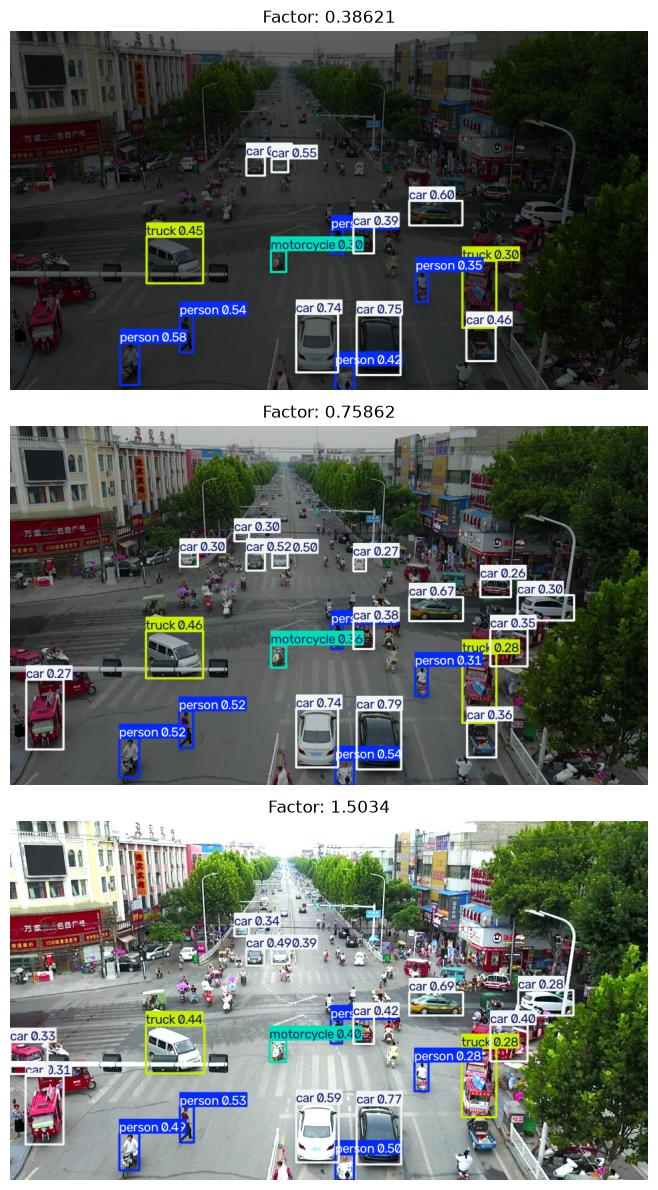

In [13]:
perturbed_metrics = []
_, ax = plt.subplots(len(VISUALIZATION_INDICES), figsize=(30, 12))
for idx, a in enumerate(augmentations):
    # reset the metric object for each dataset
    mAP_metric.reset()
    result, _, _ = evaluate(
        model=yolo_model,
        dataset=cast(od.Dataset, single_image_dataset),
        augmentation=a,
        metric=mAP_metric,
    )
    perturbed_metrics.append(result)

    if idx in VISUALIZATION_INDICES:
        # quickest way is to re-evaluate
        factor = a.augment.get_config()["factor"]
        print(f"Perturbation #{idx}: brightness perturbation value {factor:0.5}")
        datum = cast(od.Dataset, single_image_dataset)[0]
        batch = ([datum[0]], [datum[1]], [datum[2]])
        # Extract the image from the augmentation and switch it to channel last
        aug = np.transpose(a(batch)[0][0], (1, 2, 0))
        # Plot image
        ax_idx = VISUALIZATION_INDICES.index(idx)
        ax[ax_idx].imshow(model(aug[:, :, ::-1])[0].plot()[:, :, ::-1])
        ax[ax_idx].set_title(f"Factor: {factor:0.5}")
        _ = ax[ax_idx].axis("off")

plt.tight_layout()

## Evaluation Analysis

Now we can plot how the metrics (for example, mAP @ IoU=50) vary with perturbation level, keeping in mind this is the mAP scores compared against the detections in the unperturbed image.


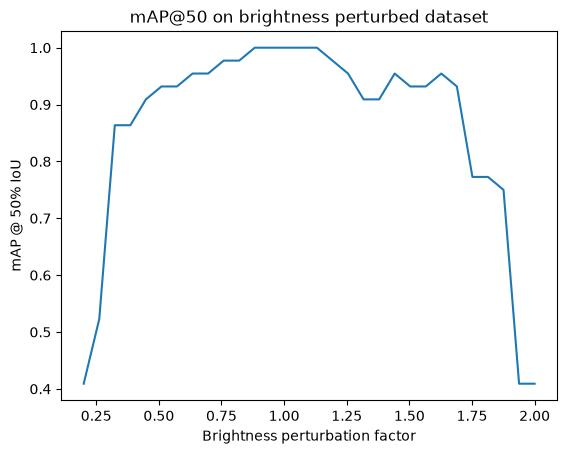

In [14]:
map50_list = [m["map_50"].item() for m in perturbed_metrics]
plt.title("mAP@50 on brightness perturbed dataset")
plt.xlabel("Brightness perturbation factor")
plt.ylabel("mAP @ 50% IoU")
_ = plt.plot(perturbation_values, map50_list)

### Evaluation Interpretation

**General things to know about mAP calculation**:
- The mAP metric calculation does not take into account the images that do not have any detection or any ground truth. In such cases, it returns the default initialization value, -1. It means it couldn't compute the metric. (Source: [link](https://github.com/Lightning-AI/torchmetrics/issues/1184#issuecomment-1589210748)). Hence, in this notebook example, we clip values to a range of `[0, 1]`.
- When having images with no ground truth, the order of those images in the batch can change the mAP calculation. To be more precise, if empty images are at the end of the batch, they will be ignored in the computation. But the empty images that are placed before the last non-empty image are taken into account. (Source: [link](https://github.com/Lightning-AI/torchmetrics/issues/1774#issuecomment-1590681234)).

Note that as plotted, the minimum y-axis value is 0.4. The metric shown, mAP@50, is the average precision of detections across all classes when the bounding box IoU is at least 0.5 (for more details, [see here](https://lightning.ai/docs/torchmetrics/stable/detection/mean_average_precision.html).) In general, we observe a perturbation value range between around 0.6 and 1.6 where the score is about 0.95 or higher, and sharp falloffs when the perturbation factor is below roughly 0.4 or above 1.75. (Note the mAP is guaranteed to be 1.0 when the perturbation is 1.0, i.e. when the image is unchanged, the two detection sets are identical.)

### Additional Plots

For further insight, we can plot the mAP per class:

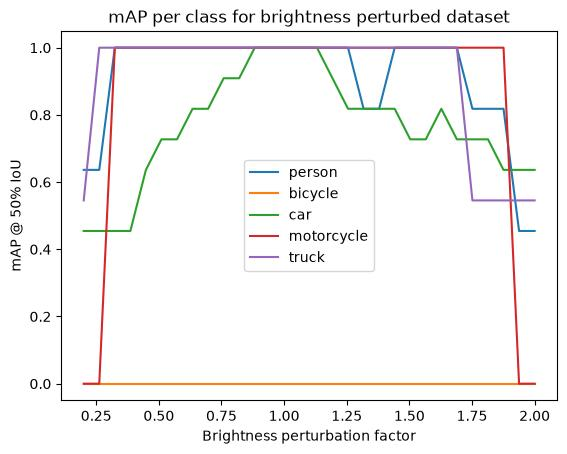

In [15]:
#
# Each instance of the metrics object has, potentially, a different set of observed classes.
# Loop through them to accumulate a unified set of classes to ensure consistent plotting across
# all thresholds.
#

unified_classes = set()
for m in perturbed_metrics:
    for class_idx in m["classes"].tolist():
        unified_classes.add(class_idx)

#
# dictionary of class_idx -> list of per-class mAP, or 0 if not present at that threshold
#

class_mAP = {class_idx: [] for class_idx in unified_classes}  # noqa: N816

#
# populate the lists across the perturbation values
#

for m in perturbed_metrics:
    this_perturbation_classes = m["classes"].tolist()
    for class_idx in unified_classes:
        if class_idx in this_perturbation_classes:
            # the index of the class in this individual metric instance
            this_class_idx = this_perturbation_classes.index(class_idx)
            class_map_value = m["map_per_class"][this_class_idx].item()
            # Clip value to 0 if negative
            if class_map_value < 0:
                class_mAP[class_idx].append(0)
            else:
                class_mAP[class_idx].append(m["map_per_class"][this_class_idx].item())
        else:
            class_mAP[class_idx].append(0)

#
# plot
#

plt.title("mAP per class for brightness perturbed dataset")
plt.xlabel("Brightness perturbation factor")
plt.ylabel("mAP @ 50% IoU")
for class_idx, class_mAP_list in class_mAP.items():  # noqa: N816
    plt.plot(perturbation_values, class_mAP_list, label=model.names[class_idx])
plt.legend()
plt.show()

The above plots shows several interesting results:

- Person, truck, and motorcycle classes are generally more robust to brightness perturbations than the car class.
- The truck and motorcycle classes show more consistent performance across the perturbation range, while cars show more variation.
- At extreme brightness perturbations (very dim or very bright), all classes experience degraded performance, which is expected as objects become harder to detect under poor lighting conditions.
- The car class shows more sensitivity to perturbations, which may be due to having more instances (15 cars vs. fewer instances of other classes) and their varied positions throughout the image.

Any conclusions about classification accuracy should be considered in light of these caveats. In particular, the foreground positioning of the detected non-car objects suggests that instead of looking at per-class results, we drill down by bounding box area. Fortunately, the metrics class supports this:


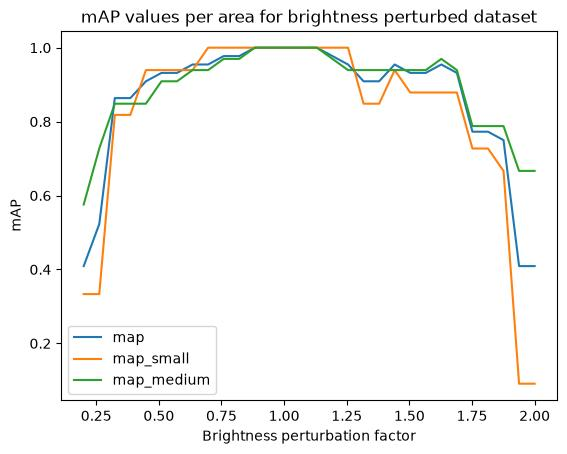

In [16]:
plt.title("mAP values per area for brightness perturbed dataset")
plt.xlabel("Brightness perturbation factor")
plt.ylabel("mAP")
for k in ("map", "map_small", "map_medium"):
    plt.plot(perturbation_values, [m[k].item() if m[k].item() >= 0 else 0 for m in perturbed_metrics], label=k)
plt.legend()
plt.show()

The `map` line covers all sizes; `map_small` and `map_medium` are the mean average precision for objects (smaller than 32^2 pixels, between 32^2 and 96^2 pixels) in area, respectively. (There are no detections in the `map_large` category.) (Here, the mAP value is averaged over a **range** of IoU thresholds, between 0.5 and 0.95.) We see that medium objects, regardless of class, are generally much more robust to brighter illumination perturbations than small ones, which makes sense when observing how objects tend to get "washed out" in the perturbation examples shown in the [Examples and Guidance](#NRTK-Brightness-perturbation:-examples-and-guidance) section above. For dimming perturbations, the situation is reversed (although not as dramatically): small objects tend to be more robust than medium, but both fall off dramatically around 0.3.


## Related How-To Guides

```{seealso}
Learn the `BrightnessPerturber` API in the [Photometric Perturbers](<project:/examples/photometric_perturbers.ipynb>) how-to guide.
```

## End of Notebook